# 3A: CDF for Allele Length Variation

In [ ]:
import pandas as pd
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sb
import matplotlib
from matplotlib.colors import to_rgba
import scipy.stats

mpl.rcParams['svg.fonttype'] = 'none'  # keep SVG text in SVGs

totalLen=pd.read_csv('statsTables/DiscoveryCohort_alleleLengthStats.TR_Explorer_1.0.1.txt.gz',sep='\t')

# calculate percentile of standard deviation
totalLen['percentile_stdev']=totalLen.loc[:,'std'].rank(pct=True)

# Define pathogenic and poly-alanine TRIDs
pathogenic=pd.read_csv('assets/pathogenicTRIDs_TRExplorer_v1.0.1_STRchiveFiltered_noVNTRs_withAnno.txt',sep='\t')
polyAlanineTRNames = ['ARX','NIPA1','HOXA13','PHOX2B','SOX3','HOXD13','ZIC2','RUNX2','PABPN1','FOXL2']
polyAlanineTRIDs = pathogenic.loc[pathogenic['geneName'].isin(polyAlanineTRNames),'TRID'].values
singleShiftTRNames = ['MIR7-2','COMP']
singleShiftTRIDs = pathogenic.loc[pathogenic['geneName'].isin(singleShiftTRNames),'TRID'].values
otherPathogenicTRIDs = pathogenic.loc[~pathogenic['geneName'].isin(polyAlanineTRNames),:]
otherPathogenicTRIDs = otherPathogenicTRIDs.loc[~otherPathogenicTRIDs['geneName'].isin(singleShiftTRNames),'TRID'].values
allPathogenicTRIDs = pathogenic.loc[:,'TRID'].values

# mark pathogenic TRs
totalLen['patho']=0
totalLen.loc[totalLen['TRID'].isin(otherPathogenicTRIDs),'patho']=1


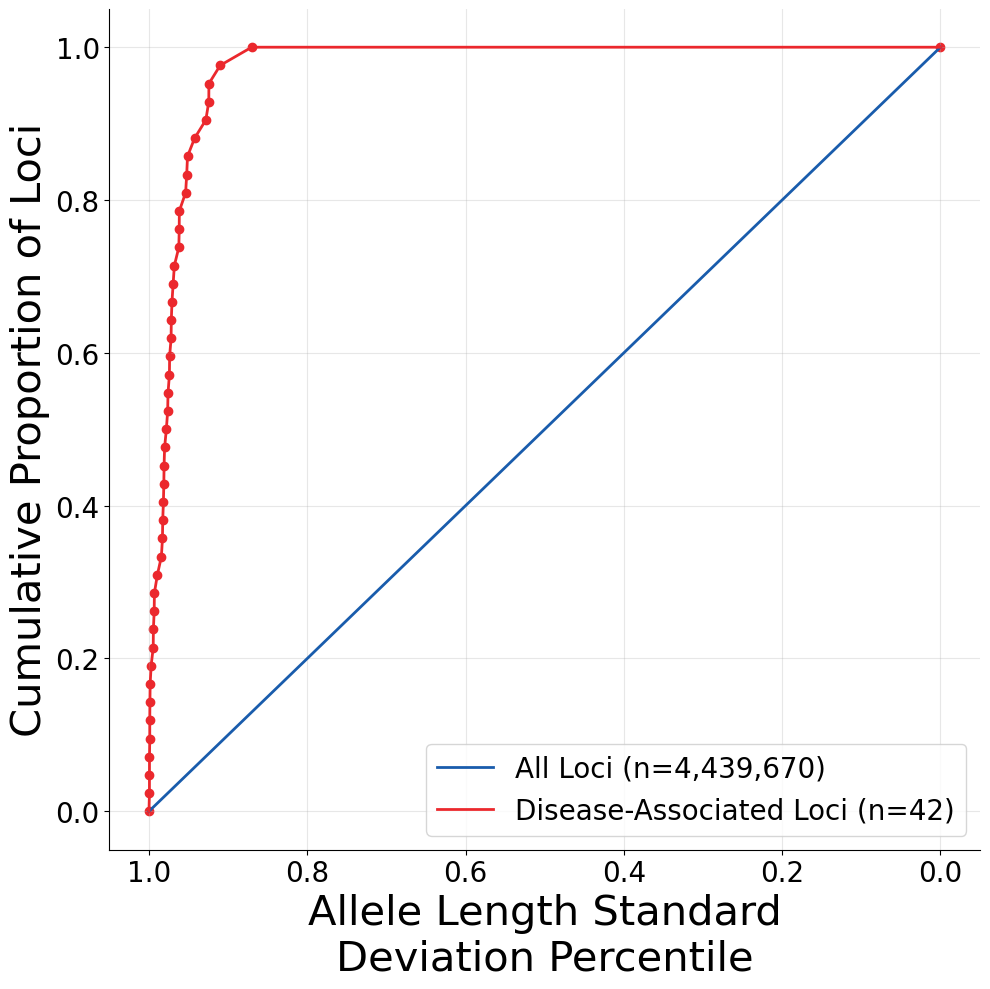

In [3]:
# Create CDF plot comparing all loci vs disease-associated loci based on std
colorPalette=['#FFF672','#F9A31B','#EB282D','#F1378A','#9D1E89','#195CAC','#06AF9B','#C7D92F','#64CCF5','0.6']

fig, ax = plt.subplots(figsize=(10, 10))

# Get std values for all loci and disease-associated loci
totalLen['percentile_stdev']=totalLen['std'].rank(pct=True,method='first')

all_std = totalLen['percentile_stdev'].dropna().values
disease_std = totalLen.loc[totalLen['patho']==1, 'percentile_stdev'].dropna().values

# Sort values for CDF
all_std_sorted = np.sort(all_std)
disease_std_sorted = np.sort(disease_std)

# Calculate cumulative probabilities (reversed to go from 1 to 0)
all_cdf = np.arange(len(all_std_sorted), 0, -1) / len(all_std_sorted)
disease_cdf = np.arange(len(disease_std_sorted), 0, -1) / len(disease_std_sorted)

# Add dummy points to make the disease line go all the way across
disease_std_sorted = np.concatenate([[0], disease_std_sorted, [1.0]])
disease_cdf = np.concatenate([[1.0], disease_cdf, [0]])

# Plot CDFs
ax.plot(all_std_sorted, all_cdf, color='#195CAC', linewidth=2, label=f'All Loci (n={len(all_std_sorted):,})')
ax.plot(disease_std_sorted, disease_cdf, color='#EB282D', linewidth=2, label=f'Disease-Associated Loci (n={len(disease_std_sorted)-2})')
ax.scatter(disease_std_sorted, disease_cdf, marker='o', color='#EB282D')


# Customize plot
ax.set_xlabel('Allele Length Standard\nDeviation Percentile', fontsize=30)
ax.set_ylabel('Cumulative Proportion of Loci', fontsize=30)
#ax.set_title('CDF of Allele Length Standard Deviation', fontsize=16, fontweight='bold')
ax.legend(fontsize=20)
ax.tick_params(labelsize=20)
ax.grid(alpha=0.3)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.invert_xaxis()

plt.tight_layout()
plt.savefig('figures/Figure3A.svg')
plt.savefig('figures/Figure3A.png',dpi=600)

# 3B: Forest Plot

In [ ]:
import pandas as pd
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sb
import matplotlib
from matplotlib.colors import to_rgba
import scipy.stats

mpl.rcParams['svg.fonttype'] = 'none'  # keep SVG text in SVGs

totalLen=pd.read_csv('statsTables/DiscoveryCohort_alleleLengthStats.TR_Explorer_1.0.1.txt.gz',sep='\t')

# calculate percentile of standard deviation
totalLen['percentile_stdev']=totalLen.loc[:,'std'].rank(pct=True)

# Define pathogenic and poly-alanine TRIDs
pathogenic=pd.read_csv('assets/pathogenicTRIDs_TRExplorer_v1.0.1_STRchiveFiltered_noVNTRs_withAnno.txt',sep='\t')
polyAlanineTRNames = ['ARX','NIPA1','HOXA13','PHOX2B','SOX3','HOXD13','ZIC2','RUNX2','PABPN1','FOXL2']
polyAlanineTRIDs = pathogenic.loc[pathogenic['geneName'].isin(polyAlanineTRNames),'TRID'].values
singleShiftTRNames = ['MIR7-2','COMP']
singleShiftTRIDs = pathogenic.loc[pathogenic['geneName'].isin(singleShiftTRNames),'TRID'].values
otherPathogenicTRIDs = pathogenic.loc[~pathogenic['geneName'].isin(polyAlanineTRNames),:]
otherPathogenicTRIDs = otherPathogenicTRIDs.loc[~otherPathogenicTRIDs['geneName'].isin(singleShiftTRNames),'TRID'].values
allPathogenicTRIDs = pathogenic.loc[:,'TRID'].values

# mark pathogenic TRs
totalLen['patho']=0
totalLen.loc[totalLen['TRID'].isin(otherPathogenicTRIDs),'patho']=1

from numba import jit
@jit(nopython=True)
def compute_u_statistic(group1, group2):
    """JIT-compiled U statistic calculation"""
    u_stat = 0
    for val1 in group1:
        u_stat += np.sum(val1 > group2)
    return u_stat

def bootstrap_odds_ratio_numba(group1, group2, n_iterations=100, random_state=42):
    """Ultra-fast bootstrap using numba JIT compilation"""
    np.random.seed(random_state)
    n1 = len(group1)
    n2 = len(group2)
    odds_ratios = np.zeros(n_iterations)
    
    for i in range(n_iterations):
        boot_group1 = np.random.choice(group1, size=n1, replace=True)
        boot_group2 = np.random.choice(group2, size=n2, replace=True)
        u_stat_boot = compute_u_statistic(boot_group1, boot_group2)
        prob_sup = u_stat_boot / (n1 * n2)
        odds_ratios[i] = prob_sup / (1 - prob_sup + 1e-9)
    
    ci_lower = np.percentile(odds_ratios, 2.5)
    ci_upper = np.percentile(odds_ratios, 97.5)
    u_stat, p_value = scipy.stats.mannwhitneyu(group1, group2, alternative='greater')
    return ci_lower, ci_upper, odds_ratios, p_value

def calculate_generalized_odds_ratio(group1, group2):
    u_stat, p_value = scipy.stats.mannwhitneyu(group1, group2, alternative='greater')
    n1=len(group1)
    n2=len(group2)
    prob_superiority = u_stat / (n1*n2)
    odds_ratio = prob_superiority / (1 - prob_superiority + 1e-9)
    ci_lower, ci_upper, _, _ = bootstrap_odds_ratio_numba(group1, group2)
    return p_value, odds_ratio, ci_lower, ci_upper

# Initialize collection variable to track results across conditions
results_collection = []

# note: we analyze more columns here than are plotted in the actual figure
for column in ['std','50thPercentile','99thPercentile','99.9thPercentile','100thPercentile','mean','mad','mode','uniqueLengths','uniqueAlleleSeqs']:
    # Calculate odds ratio with CI for a set of values
    group1=totalLen.loc[totalLen['patho']==1,column].dropna().values
    group2=totalLen.loc[:,column].dropna().values
    p_value, odds_ratio, ci_lower, ci_upper = calculate_generalized_odds_ratio(group1, group2)
    print(f"P-Value: {p_value}")
    print(f"95% Confidence Interval: [{ci_lower:.4f}, {ci_upper:.4f}]")
    print(f"Generalized Odds Ratio: {odds_ratio:.4f} (95% CI: {ci_lower:.4f}-{ci_upper:.4f})")

    # Store results for this condition
    results_collection.append({
        'condition': f'Allele Length {column}',
        'p_value': p_value,
        'odds_ratio': odds_ratio,
        'ci_lower': ci_lower,
        'ci_upper': ci_upper
    })

P-Value: 2.2656852158001278e-29
95% Confidence Interval: [25.6591, 46.7542]
Generalized Odds Ratio: 34.0906 (95% CI: 25.6591-46.7542)
P-Value: 4.816503034939887e-26
95% Confidence Interval: [13.1550, 35.7405]
Generalized Odds Ratio: 24.0975 (95% CI: 13.1550-35.7405)
P-Value: 5.398168330695549e-28
95% Confidence Interval: [35.9850, 62.2904]
Generalized Odds Ratio: 46.6564 (95% CI: 35.9850-62.2904)
P-Value: 2.9557797279857394e-28
95% Confidence Interval: [40.9800, 75.4016]
Generalized Odds Ratio: 54.6918 (95% CI: 40.9800-75.4016)
P-Value: 2.024612448651401e-27
95% Confidence Interval: [29.5664, 50.8139]
Generalized Odds Ratio: 38.8612 (95% CI: 29.5664-50.8139)
P-Value: 1.0254810806390063e-26
95% Confidence Interval: [25.5377, 45.8981]
Generalized Odds Ratio: 33.2743 (95% CI: 25.5377-45.8981)
P-Value: 2.354468420135967e-15
95% Confidence Interval: [1.6394, 6.0839]
Generalized Odds Ratio: 6.2064 (95% CI: 1.6394-6.0839)
P-Value: 1.7036130374879899e-25
95% Confidence Interval: [11.7442, 33.9

In [2]:
# repeat, normalized to reference motif length
# calculate reference motif  length
totalLen[['chr','start','end','refMotif']]=totalLen.loc[:,'TRID'].str.split(',',expand=True).iloc[:,0].str.split('-',expand=True)
totalLen['motifLen']=totalLen.loc[:,'refMotif'].str.len()

# calculate percentile of standard deviation grouped by ref motif length
totalLen['percentile_stdev']=totalLen.groupby('motifLen',observed=True)['std'].rank(pct=True)

# calculate generalized odds ratio for this statistic
group1=totalLen.loc[totalLen['patho']==1,'percentile_stdev'].dropna().values
group2=totalLen.loc[:,'percentile_stdev'].dropna().values
p_value, odds_ratio, ci_lower, ci_upper = calculate_generalized_odds_ratio(group1, group2)
print(f"P-Value: {p_value}")
print(f"95% Confidence Interval: [{ci_lower:.4f}, {ci_upper:.4f}]")
print(f"Generalized Odds Ratio: {odds_ratio:.4f} (95% CI: {ci_lower:.4f}-{ci_upper:.4f})")

# Store results for this condition
results_collection.append({
    'condition': 'Allele Length (Ref Motif Normalized)',
    'p_value': p_value,
    'odds_ratio': odds_ratio,
    'ci_lower': ci_lower,
    'ci_upper': ci_upper
})


P-Value: 2.1713575348699846e-28
95% Confidence Interval: [52.0076, 80.7234]
Generalized Odds Ratio: 65.4130 (95% CI: 52.0076-80.7234)


In [ ]:
# repeat for LPS length
lps=pd.read_csv('statsTables/DiscoveryCohort_lpsPerMotifStats.TR_Explorer_1.0.1.txt.gz',sep='\t')

# drop to the most common LPS motif per locus
lps=lps.sort_values(by=['TRID','N_motif'],ascending=False).drop_duplicates(subset='TRID',keep='first').reset_index(drop=True)


# function to convert motifs to their simplest rotational form with reverse complements
def complement(seq):
    complement = {'A': 'T', 'C': 'G', 'G': 'C', 'T': 'A'} 
    bases = list(seq) 
    bases = [complement[base] for base in bases] 
    return ''.join(bases)
def reverse_complement(seq):
    return complement(seq[::-1])
def simplest_motif(motif):
    i = (motif+motif).find(motif, 1, -1)
    if i != -1:
        motif = motif[:i]
    motifs = []
    b = len(motif)
    for i in range(b):
        c = motif[i:]+motif[:i]
        motifs.append(c)
    motifs = [x.upper() for x in motifs]
    # repeat with reverse complement
    motifRC=reverse_complement(motif.upper())
    i = (motifRC+motifRC).find(motifRC, 1, -1)
    if i != -1:
        motifRC = motifRC[:i]
    b = len(motifRC)
    for i in range(b):
        c = motifRC[i:]+motifRC[:i]
        motifs.append(c)    
    return(min(motifs))

# apply the simplest_motif function the data
lps['simpleMotif']=lps.loc[:,'LPS_Motif'].apply(simplest_motif)
lps['motifLen']=lps.loc[:,'simpleMotif'].str.len()

# calculate percentile of standard deviation 
lps['percentile_stdev']=lps.loc[:,'std'].rank(pct=True)

# mark pathogenic TRs
lps['patho']=0
lps.loc[lps['TRID'].isin(otherPathogenicTRIDs),'patho']=1

for column in ['percentile_stdev','mean','mad','mode']:
    # Calculate odds ratio with CI for a set of values
    group1=lps.loc[lps['patho']==1,column].dropna().values
    group2=lps.loc[:,column].dropna().values
    p_value, odds_ratio, ci_lower, ci_upper = calculate_generalized_odds_ratio(group1, group2)
    print(f"P-Value: {p_value}")
    print(f"95% Confidence Interval: [{ci_lower:.4f}, {ci_upper:.4f}]")
    print(f"Generalized Odds Ratio: {odds_ratio:.4f} (95% CI: {ci_lower:.4f}-{ci_upper:.4f})")

    # Store results for this condition
    results_collection.append({
        'condition': f'LPS Length {column}',
        'p_value': p_value,
        'odds_ratio': odds_ratio,
        'ci_lower': ci_lower,
        'ci_upper': ci_upper
    })

P-Value: 1.1378628249111665e-30
95% Confidence Interval: [46.2962, 106.2463]
Generalized Odds Ratio: 68.5805 (95% CI: 46.2962-106.2463)
P-Value: 4.954587010102777e-28
95% Confidence Interval: [44.8220, 77.1479]
Generalized Odds Ratio: 56.9652 (95% CI: 44.8220-77.1479)
P-Value: 3.5261018568938506e-14
95% Confidence Interval: [1.4310, 4.0517]
Generalized Odds Ratio: 5.2738 (95% CI: 1.4310-4.0517)
P-Value: 3.419553216943674e-27
95% Confidence Interval: [16.4428, 51.4135]
Generalized Odds Ratio: 30.4767 (95% CI: 16.4428-51.4135)


In [4]:
# repeat with LPS length normalized within LPS motif length
# calculate percentile of standard deviation within each motif length
lps['percentile_stdev']=lps.groupby('motifLen',observed=True)['std'].rank(pct=True)

# calculate generalized odds ratio for this statistic
group1=lps.loc[lps['patho']==1,'percentile_stdev'].dropna().values
group2=lps.loc[:,'percentile_stdev'].dropna().values
p_value, odds_ratio, ci_lower, ci_upper = calculate_generalized_odds_ratio(group1, group2)
print(f"P-Value: {p_value}")
print(f"95% Confidence Interval: [{ci_lower:.4f}, {ci_upper:.4f}]")
print(f"Generalized Odds Ratio: {odds_ratio:.4f} (95% CI: {ci_lower:.4f}-{ci_upper:.4f})")

# Store results for this condition
results_collection.append({
    'condition': 'LPS Length (LPS Motif Normalized)',
    'p_value': p_value,
    'odds_ratio': odds_ratio,
    'ci_lower': ci_lower,
    'ci_upper': ci_upper
})

# Display summary of all collected results
print("\n" + "="*80)
print("SUMMARY OF ALL CONDITIONS")
print("="*80)
results_df = pd.DataFrame(results_collection)
print(results_df.to_string(index=False))

P-Value: 1.6188698958380048e-29
95% Confidence Interval: [148.9448, 564.5462]
Generalized Odds Ratio: 243.8534 (95% CI: 148.9448-564.5462)

SUMMARY OF ALL CONDITIONS
                           condition      p_value  odds_ratio   ci_lower   ci_upper
                   Allele Length std 2.265685e-29   34.090647  25.659092  46.754154
        Allele Length 50thPercentile 4.816503e-26   24.097494  13.155032  35.740496
        Allele Length 99thPercentile 5.398168e-28   46.656401  35.985013  62.290424
      Allele Length 99.9thPercentile 2.955780e-28   54.691771  40.980000  75.401561
       Allele Length 100thPercentile 2.024612e-27   38.861175  29.566429  50.813891
                  Allele Length mean 1.025481e-26   33.274346  25.537734  45.898146
                   Allele Length mad 2.354468e-15    6.206384   1.639378   6.083870
                  Allele Length mode 1.703613e-25   21.159940  11.744171  33.945598
         Allele Length uniqueLengths 3.265884e-25   53.057892  35.390443  72.7

In [5]:
# Add several more conditions based on other theories:
# Distance to: eSTRs, TAD boundaries in DLPFC, RAD21 binding sites in neural cells, SMC3 binding sites in neural cells, ORegAnno elements, and Alu elements

In [ ]:
%%bash
# how we computed those distances:
# ORegAnno, RAD21, SMC3, and repeatMasker were downloaded from the UCSC table browser
# eSTRs were collected from Fotsing, et al 2019 and lifted over to hg38
# DLPFC HiC data was obtained from https://3dgenome.fsm.northwestern.edu/datasets?id=44

# create TAD boundaries bed file:
awk -F'\t' -v OFS='\t' '{print $1,$2,$2+1"\n"$1,$3,$3+1}' DLPFC_ENCSR538WAP_tad.bed | uniq | bedtools sort -i stdin > DLPFC_TAD_Boundaries.bed
# reformat other files as bed
zcat neuralCell_RAD21_hg38.txt.gz | tail -n +2 | cut -f 2,3,4 | bedtools sort -i stdin > neuralCell_RAD21.bed
zcat neuralCell_SMC3_hg38.txt.gz | tail -n +2 | cut -f 2,3,4 | bedtools sort -i stdin > neuralCell_SMC3.bed
zcat oreganno.txt.gz | cut -f 2,3,4 | bedtools sort -i stdin > oreganno.bed
zcat repeatMasker_hg38.txt.gz | grep 'Alu' | cut -f 6,7,8 | bedtools sort -i stdin > Alus.bed

# get distance to closest element for each TR in the catalog
bedtools closest -d -a variation_clusters_and_isolated_TRs_v1.0.1.hg38.TRGT.bed.gz -b DLPFC_TAD_Boundaries.bed | cut -f 4,8 | tr ';' '\t' | sed 's/ID=//' | cut -f 1,4 | gzip -c > distanceToClosestTADBoundary.txt.gz
bedtools closest -d -a variation_clusters_and_isolated_TRs_v1.0.1.hg38.TRGT.bed.gz -b neuralCell_RAD21.bed | cut -f 4,8 | tr ';' '\t' | sed 's/ID=//' | cut -f 1,4 | gzip -c > distanceToClosestRAD21Site.txt.gz
bedtools closest -d -a variation_clusters_and_isolated_TRs_v1.0.1.hg38.TRGT.bed.gz -b neuralCell_SMC3.bed | cut -f 4,8 | tr ';' '\t' | sed 's/ID=//' | cut -f 1,4 | gzip -c > distanceToClosestSMC3Site.txt.gz
bedtools closest -d -a variation_clusters_and_isolated_TRs_v1.0.1.hg38.TRGT.bed.gz -b oreganno.bed | cut -f 4,8 | tr ';' '\t' | sed 's/ID=//' | cut -f 1,4 | gzip -c > distanceToClosestORegAnnoFeature.txt.gz
bedtools closest -d -a variation_clusters_and_isolated_TRs_v1.0.1.hg38.TRGT.bed.gz -b Alus.bed | cut -f 4,8 | tr ';' '\t' | sed 's/ID=//' | cut -f 1,4 | gzip -c > distanceToClosestAlu.txt.gz
bedtools closest -d -a variation_clusters_and_isolated_TRs_v1.0.1.hg38.TRGT.bed.gz -b eSTR_CAVIAR_0.3_hg38.bed | cut -f 4,8 | tr ';' '\t' | sed 's/ID=//' | cut -f 1,4 | gzip -c > distanceToClosestESTR.txt.gz


In [18]:
tad=pd.read_csv('assets/pathoEnrichment/distanceToClosestTADBoundary.txt.gz',sep='\t',header=None,names=['TRID','TADDistance'])
rad21=pd.read_csv('assets/pathoEnrichment/distanceToClosestRAD21Site.txt.gz',sep='\t',header=None,names=['TRID','RAD21Distance'])
smc3=pd.read_csv('assets/pathoEnrichment/distanceToClosestSMC3Site.txt.gz',sep='\t',header=None,names=['TRID','SMC3Distance'])
oreganno=pd.read_csv('assets/pathoEnrichment/distanceToClosestORegAnnoFeature.txt.gz',sep='\t',header=None,names=['TRID','ORegAnnoDistance'])
alu=pd.read_csv('assets/pathoEnrichment/distanceToClosestAlu.txt.gz',sep='\t',header=None,names=['TRID','AluDistance'])
eSTR=pd.read_csv('assets/pathoEnrichment/distanceToClosestESTR.txt.gz',sep='\t',header=None,names=['TRID','eSTRDistance'])

combined=totalLen.merge(tad,how='inner',on='TRID')
combined=combined.merge(rad21,how='inner',on='TRID')
combined=combined.merge(smc3,how='inner',on='TRID')
combined=combined.merge(oreganno,how='inner',on='TRID')
combined=combined.merge(alu,how='inner',on='TRID')
combined=combined.merge(eSTR,how='inner',on='TRID')


for column in ['TADDistance','RAD21Distance','SMC3Distance','ORegAnnoDistance','AluDistance','eSTRDistance']:
    # Calculate odds ratio with CI for a set of values
    group1=combined.loc[:,column].dropna().values
    group2=combined.loc[combined['patho']==1,column].dropna().values
    p_value, odds_ratio, ci_lower, ci_upper = calculate_generalized_odds_ratio(group1, group2)
    print(f"P-Value: {p_value}")
    print(f"95% Confidence Interval: [{ci_lower:.4f}, {ci_upper:.4f}]")
    print(f"Generalized Odds Ratio: {odds_ratio:.4f} (95% CI: {ci_lower:.4f}-{ci_upper:.4f})")

    # Store results for this condition
    results_collection.append({
        'condition': f'{column}',
        'p_value': p_value,
        'odds_ratio': odds_ratio,
        'ci_lower': ci_lower,
        'ci_upper': ci_upper
    })

# Display summary of all collected results
print("\n" + "="*80)
print("SUMMARY OF ALL CONDITIONS")
print("="*80)
results_df = pd.DataFrame(results_collection)
print(results_df.to_string(index=False))


P-Value: 0.01239761209882126
95% Confidence Interval: [1.0287, 1.4889]
Generalized Odds Ratio: 1.2599 (95% CI: 1.0287-1.4889)
P-Value: 1.607554308637269e-29
95% Confidence Interval: [2.7639, 4.7466]
Generalized Odds Ratio: 3.7045 (95% CI: 2.7639-4.7466)
P-Value: 1.177096987107588e-41
95% Confidence Interval: [3.8329, 7.2405]
Generalized Odds Ratio: 5.4534 (95% CI: 3.8329-7.2405)
P-Value: 5.560531771886395e-46
95% Confidence Interval: [3.3330, 4.9346]
Generalized Odds Ratio: 6.2965 (95% CI: 3.3330-4.9346)
P-Value: 0.9999999999999912
95% Confidence Interval: [0.3641, 0.4879]
Generalized Odds Ratio: 0.4393 (95% CI: 0.3641-0.4879)
P-Value: 9.034775999099747e-14
95% Confidence Interval: [1.8648, 2.7896]
Generalized Odds Ratio: 2.2111 (95% CI: 1.8648-2.7896)

SUMMARY OF ALL CONDITIONS
                           condition      p_value  odds_ratio   ci_lower   ci_upper
                   Allele Length std 2.265685e-29   34.090647  25.659092  46.754154
        Allele Length 50thPercentile 4.816

In [22]:
# Save results_collection to file
import pickle
with open('assets/pathoEnrichment/results_collection_figure3B.pkl', 'wb') as f:
    pickle.dump(results_collection, f)
print(f"Saved results_collection with {len(results_collection)} entries")

Saved results_collection with 22 entries


C:\Users\Matt\AppData\Local\Temp\ipykernel_71896\3812438865.py:98: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax.set_xticklabels(['0.01','0.1','1','10','100','1000'],fontsize=20)


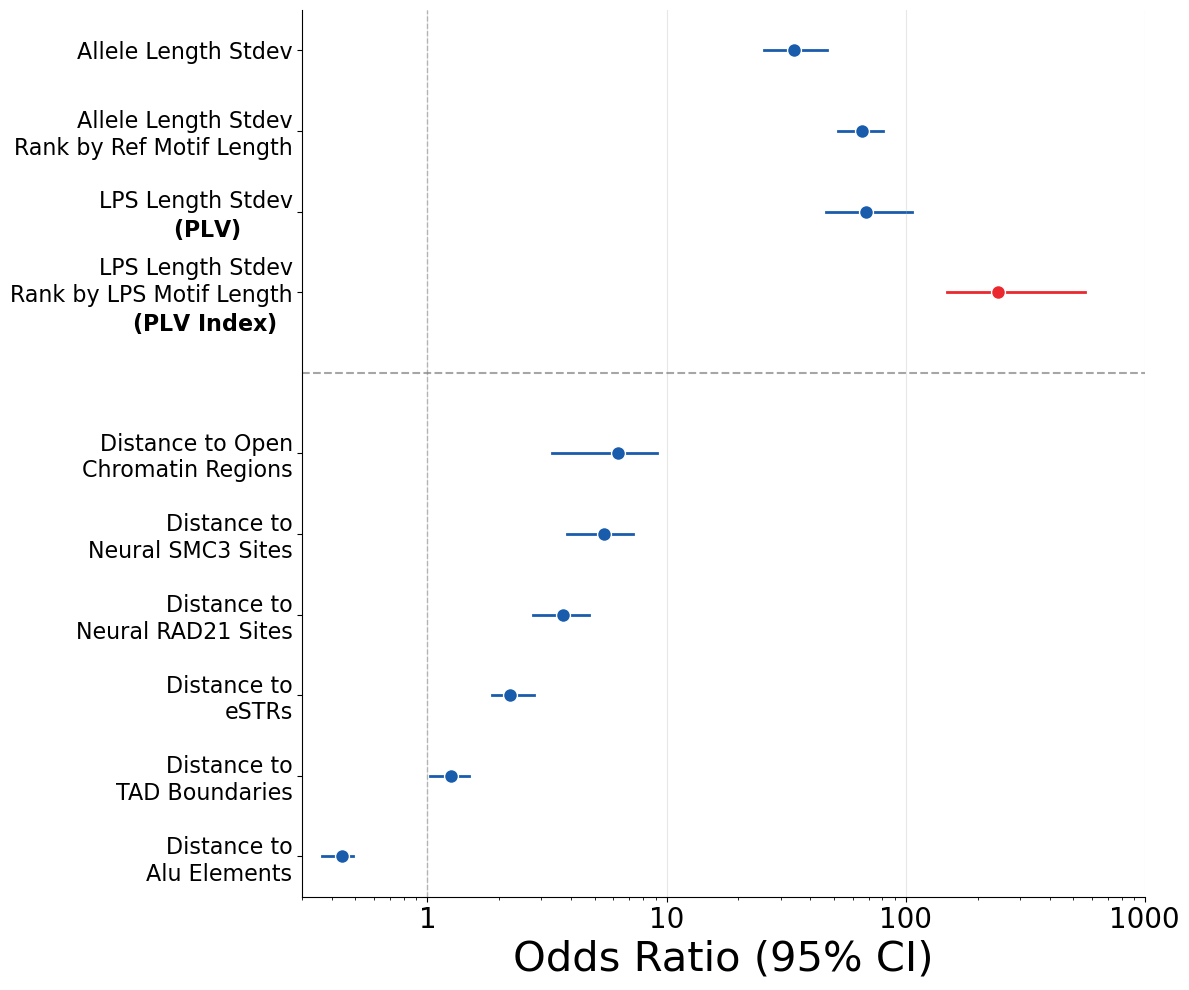

In [29]:
# plot results
import pickle
with open('assets/pathoEnrichment/results_collection_figure3B.pkl', 'rb') as f:
    results_collection_loaded = pickle.load(f)

# Create forest plot for Figure 3B
import matplotlib.pyplot as plt
import matplotlib as mpl
import pandas as pd
import numpy as np

mpl.rcParams['svg.fonttype'] = 'none'

# Convert to DataFrame
forest_df = pd.DataFrame(results_collection_loaded)

# Define the top four entries in order
top_four = [
    'Allele Length std',
    'Allele Length (Ref Motif Normalized)',
    'LPS Length percentile_stdev',
    'LPS Length (LPS Motif Normalized)'
]

# Separate top four from the rest
top_df = forest_df[forest_df['condition'].isin(top_four)].copy()
# Sort by the order specified
top_df['sort_order'] = top_df['condition'].map({cond: i for i, cond in enumerate(top_four)})
top_df = top_df.sort_values('sort_order')

# Get the rest that we want to plot
remaining = ['ORegAnnoDistance','SMC3Distance','RAD21Distance','AluDistance','eSTRDistance','TADDistance']
rest_df = forest_df[forest_df['condition'].isin(remaining)].copy()
rest_df = rest_df.sort_values('odds_ratio', ascending=False)

# rename labels as desired
top_df.loc[top_df['condition'] == 'LPS Length percentile_stdev', 'condition'] = 'LPS Length Stdev\n$\\bf{(PLV)}$        '
top_df.loc[top_df['condition'] == 'Allele Length std', 'condition'] = 'Allele Length Stdev'
top_df.loc[top_df['condition'] == 'Allele Length (Ref Motif Normalized)', 'condition'] = 'Allele Length Stdev\nRank by Ref Motif Length'
top_df.loc[top_df['condition'] == 'LPS Length (LPS Motif Normalized)', 'condition'] = 'LPS Length Stdev\nRank by LPS Motif Length\n$\\bf{(PLV\ Index)}$   '
rest_df.loc[rest_df['condition'] == 'ORegAnnoDistance','condition'] = 'Distance to Open\nChromatin Regions'
rest_df.loc[rest_df['condition'] == 'SMC3Distance','condition'] = 'Distance to\nNeural SMC3 Sites'
rest_df.loc[rest_df['condition'] == 'RAD21Distance','condition'] = 'Distance to\nNeural RAD21 Sites'
rest_df.loc[rest_df['condition'] == 'AluDistance','condition'] = 'Distance to\nAlu Elements'
rest_df.loc[rest_df['condition'] == 'eSTRDistance','condition'] = 'Distance to\neSTRs'
rest_df.loc[rest_df['condition'] == 'TADDistance','condition'] = 'Distance to\nTAD Boundaries'

# Create the plot
fig, ax = plt.subplots(figsize=(12, 10))

# Combine for plotting (top four + rest)
y_positions = []
labels = []
odds_ratios = []
ci_lowers = []
ci_uppers = []

# Add top four
current_y = len(top_df) + len(rest_df) + 1  # Add extra space for gap
for idx, row in top_df.iterrows():
    y_positions.append(current_y)
    labels.append(row['condition'])
    odds_ratios.append(row['odds_ratio'])
    ci_lowers.append(row['ci_lower'])
    ci_uppers.append(row['ci_upper'])
    current_y -= 1

# Add separator in the middle of a gap
separator_y = current_y  # Middle of the gap
current_y -= 1  # Skip 1 units for gap

# Add rest
for idx, row in rest_df.iterrows():
    y_positions.append(current_y)
    labels.append(row['condition'])
    odds_ratios.append(row['odds_ratio'])
    ci_lowers.append(row['ci_lower'])
    ci_uppers.append(row['ci_upper'])
    current_y -= 1

# Plot points and error bars
colors = ['#EB282D' if i == len(top_df)-1 else '#195CAC' for i in range(len(y_positions))]
for i, (y, or_val, ci_l, ci_u, color) in enumerate(zip(y_positions, odds_ratios, ci_lowers, ci_uppers, colors)):
    ax.plot([ci_l, ci_u], [y, y], color=color, linewidth=2, zorder=1)
    ax.scatter(or_val, y, s=100, color=color, zorder=2, edgecolors='white', linewidth=1)

# Add vertical line at OR=1
ax.axvline(x=1, color='gray', linestyle='--', linewidth=1, alpha=0.5)

# Add horizontal dashed line separator between top four and rest
ax.axhline(y=separator_y, color='gray', linestyle='--', linewidth=1.5, alpha=0.7)

# Customize axes
ax.set_yticks(y_positions)
ax.set_yticklabels(labels, fontsize=16)
ax.set_xlabel('Odds Ratio (95% CI)', fontsize=30)
ax.set_xscale('log')
ax.set_xticklabels(['0.01','0.1','1','10','100','1000'],fontsize=20)
ax.set_xlim([0.3, 1000])
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.savefig('figures/Figure3B.svg')
plt.savefig('figures/Figure3B.png', dpi=600)
plt.show()


# 3C: Pathogenic Enrichment by Motif

C:\Users\Matt\AppData\Local\Temp\ipykernel_71896\3286629724.py:76: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  counts = pathoMotifs.groupby('simpleMotif').size().reindex(motifs, fill_value=0).tolist()
C:\Users\Matt\AppData\Local\Temp\ipykernel_71896\3286629724.py:84: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: x.sample(frac=1, random_state=42))
c:\Users\Matt\anaconda3\lib\site-packages\seaborn\_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future 

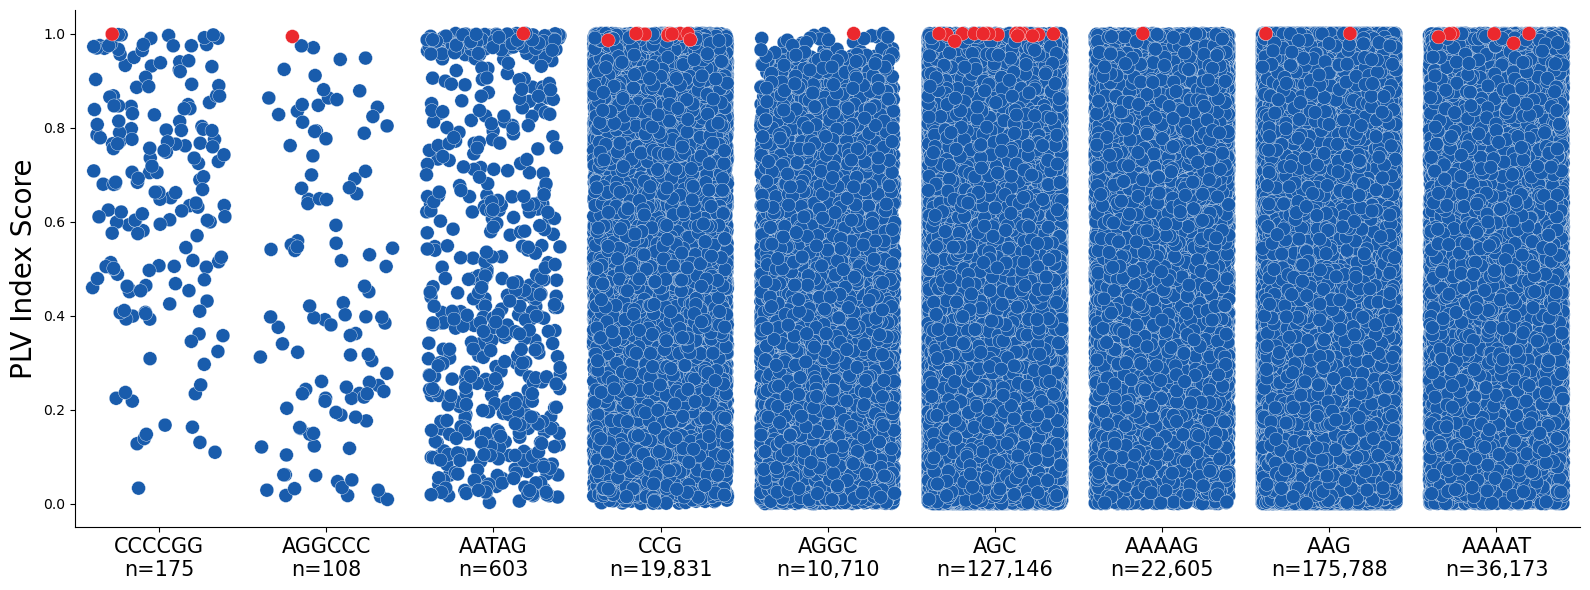

In [ ]:
# initial data loading and package import
import pandas as pd
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sb
import matplotlib
from matplotlib.colors import to_rgba

mpl.rcParams['svg.fonttype'] = 'none'  # keep SVG text in SVGs
lps=pd.read_csv('statsTables/DiscoveryCohort_lpsPerMotifStats.TR_Explorer_1.0.1.txt.gz',sep='\t')
# rescue CNBP
lps=lps.loc[~((lps['TRID']=='3-129172576-129172656-CAGG,3-129172656-129172696-CAGA,3-129172691-129172693-AC,3-129172696-129172732-CA') & (lps['LPS_Motif'].isin(['AC','ACAG']))),:]

# drop to the most common LPS motif per locus
lps=lps.sort_values(by=['TRID','N_motif'],ascending=False).drop_duplicates(subset='TRID',keep='first').reset_index(drop=True)

# function to convert motifs to their simplest rotational form with reverse complements
def complement(seq):
    complement = {'A': 'T', 'C': 'G', 'G': 'C', 'T': 'A'} 
    bases = list(seq) 
    bases = [complement[base] for base in bases] 
    return ''.join(bases)
def reverse_complement(seq):
    return complement(seq[::-1])
def simplest_motif(motif):
    i = (motif+motif).find(motif, 1, -1)
    if i != -1:
        motif = motif[:i]
    motifs = []
    b = len(motif)
    for i in range(b):
        c = motif[i:]+motif[:i]
        motifs.append(c)
    motifs = [x.upper() for x in motifs]
    # repeat with reverse complement
    motifRC=reverse_complement(motif.upper())
    i = (motifRC+motifRC).find(motifRC, 1, -1)
    if i != -1:
        motifRC = motifRC[:i]
    b = len(motifRC)
    for i in range(b):
        c = motifRC[i:]+motifRC[:i]
        motifs.append(c)    
    return(min(motifs))

# apply the simplest_motif function the data
lps['simpleMotif']=lps.loc[:,'LPS_Motif'].apply(simplest_motif)
lps['motifLen']=lps.loc[:,'simpleMotif'].str.len()
# calculate percentile of standard deviation within each motif length group
lps['percentile_stdev']=lps.groupby('motifLen',observed=True)['std'].rank(pct=True, method='first')

# Motif order and subset
motifs = ['CCCCGG', 'AGGCCC', 'AATAG', 'CCG', 'AGGC', 'AGC', 'AAAAG', 'AAG', 'AAAAT']
pathoMotifs = lps.loc[lps['simpleMotif'].isin(motifs),:].copy()
pathoMotifs['simpleMotif'] = pd.Categorical(pathoMotifs['simpleMotif'], categories=motifs, ordered=True)
pathoMotifs = pathoMotifs.sort_values(['simpleMotif', 'TRID'])

# Define pathogenic and poly-alanine TRIDs
pathogenic=pd.read_csv('assets/pathogenicTRIDs_TRExplorer_v1.0.1_STRchiveFiltered_noVNTRs_withAnno.txt',sep='\t')

polyAlanineTRNames = ['ARX','NIPA1','HOXA13','PHOX2B','SOX3','HOXD13','ZIC2','RUNX2','PABPN1','FOXL2']
polyAlanineTRIDs = pathogenic.loc[pathogenic['geneName'].isin(polyAlanineTRNames),'TRID'].values
otherPathogenicTRIDs = pathogenic.loc[~pathogenic['geneName'].isin(polyAlanineTRNames),'TRID'].values
pathoMotifs['Status'] = 'Catalog'
pathoMotifs.loc[pathoMotifs['TRID'].isin(otherPathogenicTRIDs), 'Status'] = 'Disease-Associated'
# define the plotting order
pathoMotifs = pathoMotifs.sort_values(['simpleMotif', 'Status'])
# Colors
pal = {
    'Catalog':           to_rgba('#195CAC', 1),
    'Disease-Associated': to_rgba('#EB282D', 1),
}
counts = pathoMotifs.groupby('simpleMotif').size().reindex(motifs, fill_value=0).tolist()
new_labels = [f'{motif}\nn={count:,}' for motif, count in zip(motifs, counts)]

# Sort by Status to control draw order (Catalog first, then Disease-Associated, then Polyalanine)
# Then shuffle within each status group to avoid transparency artifacts
status_order = ['Catalog', 'Disease-Associated']
pathoMotifs_shuffled = (pathoMotifs
                        .groupby('Status', group_keys=False)
                        .apply(lambda x: x.sample(frac=1, random_state=42))
                        .assign(Status=lambda df: pd.Categorical(df['Status'], categories=status_order, ordered=True))
                        .sort_values('Status')
                        .reset_index(drop=True))

# Plot
fig, ax = plt.subplots(figsize=(16, 6))
sb.stripplot(
    data=pathoMotifs_shuffled,
    x='simpleMotif', y='percentile_stdev',
    hue='Status', palette=pal, jitter=0.4,
    edgecolor='white', linewidth=0.25, s=10,
    legend=False, rasterized=True
)
ax.set_xticklabels(new_labels, fontsize=15)
ax.set_xlabel('')
ax.set_ylabel('PLV Index Score', fontsize=20)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout()
fig.savefig('figures/Figure3C.svg')
fig.savefig('figures/Figure3C.png',dpi=600)


In [17]:
# print out the ranking of each pathogenic variant:
tmp=pathoMotifs.loc[pathoMotifs['Status']=='Disease-Associated',:]
pathogenic=pd.read_csv('assets/pathogenicTRIDs_TRExplorer_v1.0.1_STRchiveFiltered_noVNTRs_withAnno.txt',sep='\t')
tmp=tmp.merge(pathogenic.loc[:,['TRID','geneName']],how='inner',on='TRID')
for TRID, geneName, motif in zip(tmp.TRID.values, tmp.geneName.values, tmp.simpleMotif.values):
    thisMotifGroup=pathoMotifs.loc[pathoMotifs['simpleMotif']==motif,:].sort_values(by='percentile_stdev',ascending=False).reset_index(drop=True)
    thisTRRank=thisMotifGroup.loc[thisMotifGroup['TRID']==TRID,:].index.values[0]+1
    print(geneName + ": " + str(thisTRRank) + ' of ' + str(len(thisMotifGroup)))

C9orf72: 1 of 175
NOP56: 1 of 108
ATXN10: 3 of 603
NOTCH2NLC: 12 of 19831
ABCD3: 108 of 19831
NUTM2B-AS1: 54 of 19831
CBL: 57 of 19831
RILPL1: 505 of 19831
XYLT1: 4 of 19831
ZFHX3: 468 of 19831
GIPC1: 39 of 19831
AFF3: 6 of 19831
LRP12: 43 of 19831
FMR1: 2 of 19831
AFF2: 20 of 19831
CNBP: 2 of 10710
ATXN2: 42 of 127146
ATN1: 47 of 127146
ATXN8OS: 3 of 127146
ATXN3: 6 of 127146
THAP11: 1013 of 127146
JPH3: 82 of 127146
TCF4: 1 of 127146
CACNA1A: 87 of 127146
DMPK: 11 of 127146
GLS: 26 of 127146
ATXN7: 136 of 127146
HTT: 33 of 127146
PPP2R2B: 55 of 127146
ATXN1: 138 of 127146
TBP: 85 of 127146
AR: 37 of 127146
RFC1: 3 of 22605
FGF14: 6 of 175788
FXN: 228 of 175788
DAB1: 4 of 36173
BEAN1: 7 of 36173
STARD7: 54 of 36173
YEATS2: 400 of 36173
MARCHF6: 1146 of 36173
SAMD12: 50 of 36173


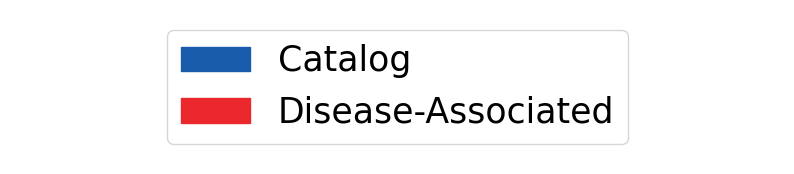

In [ ]:
# separate plot for the legend
mpl.rcParams['svg.fonttype'] = 'none'
fig_legend = plt.figure(figsize=(10, 2))
ax = fig_legend.add_subplot(111)
ax.axis('off')
           
handles=[matplotlib.patches.Circle((1, 1),  color=i) for i in ['#195CAC','#EB282D','#FFF672']]
labels = ['Catalog','Disease-Associated']

ax.legend(handles=handles, labels=labels,loc='center',prop={'size': 25}, title='')
fig.tight_layout()
fig_legend.savefig('figures/Figure3C_legend.svg')
fig_legend.savefig('figures/Figure3C_legend.png',dpi=600)


# 3D: Replication across cohorts

In [ ]:
# caluclate the proportion of the pathogenic TRs that rank above the 90th, 95th, and 99th percentiles
# initial data loading and package import
import pandas as pd
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sb
import matplotlib
from matplotlib.colors import to_rgba

mpl.rcParams['svg.fonttype'] = 'none'  # keep SVG text in SVGs

AFR=pd.read_csv('statsTables/ValidationCohort_lpsPerMotifStats_AFR.TR_Explorer_1.0.1.txt.gz',sep='\t')
AMR=pd.read_csv('statsTables/ValidationCohort_lpsPerMotifStats_AMR.TR_Explorer_1.0.1.txt.gz',sep='\t')
EUR=pd.read_csv('statsTables/ValidationCohort_lpsPerMotifStats_EUR.TR_Explorer_1.0.1.txt.gz',sep='\t')
EAS=pd.read_csv('statsTables/ValidationCohort_lpsPerMotifStats_EAS.TR_Explorer_1.0.1.txt.gz',sep='\t')
SAS=pd.read_csv('statsTables/ValidationCohort_lpsPerMotifStats_SAS.TR_Explorer_1.0.1.txt.gz',sep='\t')

# drop to the most common LPS motif per locus
AFR=AFR.sort_values(by=['TRID','N_motif'],ascending=False).drop_duplicates(subset='TRID',keep='first').reset_index(drop=True)
AMR=AMR.sort_values(by=['TRID','N_motif'],ascending=False).drop_duplicates(subset='TRID',keep='first').reset_index(drop=True)
EUR=EUR.sort_values(by=['TRID','N_motif'],ascending=False).drop_duplicates(subset='TRID',keep='first').reset_index(drop=True)
EAS=EAS.sort_values(by=['TRID','N_motif'],ascending=False).drop_duplicates(subset='TRID',keep='first').reset_index(drop=True)
SAS=SAS.sort_values(by=['TRID','N_motif'],ascending=False).drop_duplicates(subset='TRID',keep='first').reset_index(drop=True)

# function to convert motifs to their simplest rotational form with reverse complements
def complement(seq):
    complement = {'A': 'T', 'C': 'G', 'G': 'C', 'T': 'A'} 
    bases = list(seq) 
    bases = [complement[base] for base in bases] 
    return ''.join(bases)
def reverse_complement(seq):
    return complement(seq[::-1])
def simplest_motif(motif):
    i = (motif+motif).find(motif, 1, -1)
    if i != -1:
        motif = motif[:i]
    motifs = []
    b = len(motif)
    for i in range(b):
        c = motif[i:]+motif[:i]
        motifs.append(c)
    motifs = [x.upper() for x in motifs]
    # repeat with reverse complement
    motifRC=reverse_complement(motif.upper())
    i = (motifRC+motifRC).find(motifRC, 1, -1)
    if i != -1:
        motifRC = motifRC[:i]
    b = len(motifRC)
    for i in range(b):
        c = motifRC[i:]+motifRC[:i]
        motifs.append(c)    
    return(min(motifs))

# apply the simplest_motif function the data
AFR['simpleMotif']=AFR.loc[:,'LPS_Motif'].apply(simplest_motif)
AMR['simpleMotif']=AMR.loc[:,'LPS_Motif'].apply(simplest_motif)
EUR['simpleMotif']=EUR.loc[:,'LPS_Motif'].apply(simplest_motif)
EAS['simpleMotif']=EAS.loc[:,'LPS_Motif'].apply(simplest_motif)
SAS['simpleMotif']=SAS.loc[:,'LPS_Motif'].apply(simplest_motif)
# calculate percentile of standard deviation within each motif length
AFR['motifLen']=AFR.loc[:,'simpleMotif'].str.len()
AMR['motifLen']=AMR.loc[:,'simpleMotif'].str.len()
EUR['motifLen']=EUR.loc[:,'simpleMotif'].str.len()
EAS['motifLen']=EAS.loc[:,'simpleMotif'].str.len()
SAS['motifLen']=SAS.loc[:,'simpleMotif'].str.len()

AFR['percentile_stdev']=AFR.groupby('motifLen',observed=True)['std'].rank(pct=True)
AMR['percentile_stdev']=AMR.groupby('motifLen',observed=True)['std'].rank(pct=True)
EUR['percentile_stdev']=EUR.groupby('motifLen',observed=True)['std'].rank(pct=True)
EAS['percentile_stdev']=EAS.groupby('motifLen',observed=True)['std'].rank(pct=True)
SAS['percentile_stdev']=SAS.groupby('motifLen',observed=True)['std'].rank(pct=True)

# Define pathogenic and poly-alanine TRIDs
pathogenic=pd.read_csv('assets/pathogenicTRIDs_TRExplorer_v1.0.1_STRchiveFiltered_noVNTRs_withAnno.txt',sep='\t')

polyAlanineTRNames = ['ARX','NIPA1','HOXA13','PHOX2B','SOX3','HOXD13','ZIC2','RUNX2','PABPN1','FOXL2']
polyAlanineTRIDs = pathogenic.loc[pathogenic['geneName'].isin(polyAlanineTRNames),'TRID'].values
singleShiftTRNames = ['MIR7-2','COMP']
singleShiftTRIDs = pathogenic.loc[pathogenic['geneName'].isin(singleShiftTRNames),'TRID'].values
otherPathogenicTRIDs = pathogenic.loc[~pathogenic['geneName'].isin(polyAlanineTRNames),:]
otherPathogenicTRIDs = otherPathogenicTRIDs.loc[~otherPathogenicTRIDs['geneName'].isin(singleShiftTRNames),'TRID'].values



# Analyze the known pathogenic TR enrichment
AFR['patho']=0
AFR.loc[AFR['TRID'].isin(otherPathogenicTRIDs),'patho']=1
AMR['patho']=0
AMR.loc[AMR['TRID'].isin(otherPathogenicTRIDs),'patho']=1
EUR['patho']=0
EUR.loc[EUR['TRID'].isin(otherPathogenicTRIDs),'patho']=1
EAS['patho']=0
EAS.loc[EAS['TRID'].isin(otherPathogenicTRIDs),'patho']=1
SAS['patho']=0
SAS.loc[SAS['TRID'].isin(otherPathogenicTRIDs),'patho']=1



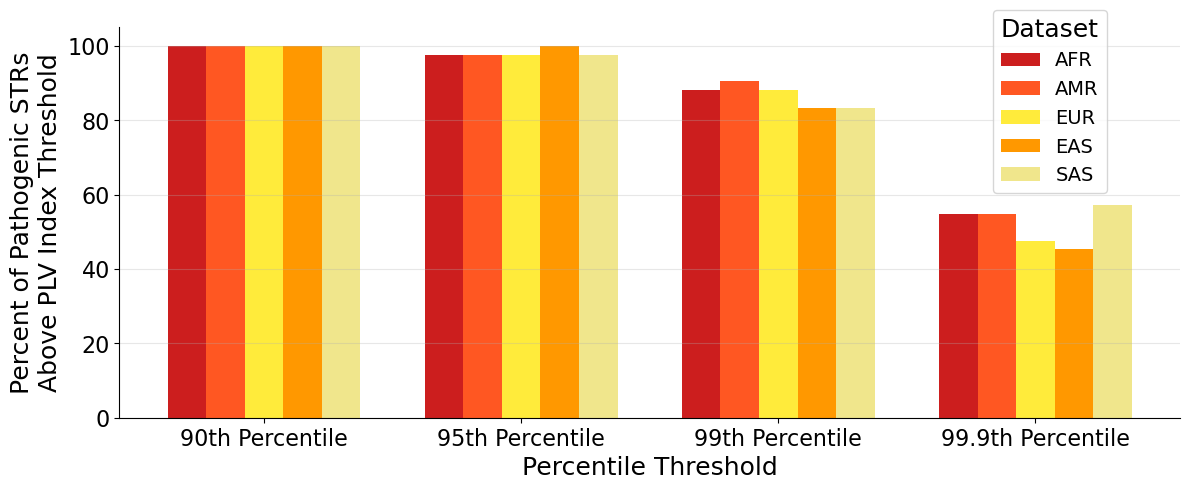

In [ ]:
from statsmodels.stats.contingency_tables import Table2x2
def calculate_enrichment_with_ci(df, percentile_threshold, pathogenic_col='patho'):
    above_threshold = df['percentile_stdev'] > percentile_threshold
    
    a = ((df[pathogenic_col] == 1) & above_threshold).sum()
    b = ((df[pathogenic_col] == 0) & above_threshold).sum()
    c = ((df[pathogenic_col] == 1) & ~above_threshold).sum()
    d = ((df[pathogenic_col] == 0) & ~above_threshold).sum()
    
    table = Table2x2([[a, b], [c, d]])
    
    return {
        'odds_ratio': table.oddsratio,
        'p_value': table.oddsratio_pvalue(),
        'ci_95': table.oddsratio_confint(alpha=0.05),
        'contingency_table': [[a, b], [c, d]],
        'n_pathogenic_above': a,
        'n_pathogenic_total': a + c,
        'n_total_above': a + b
    }


# Collect n_pathogenic_above values for plotting
thresholds = [0.90, 0.95, 0.99, 0.999]
datasets = {
    'AFR': AFR,
    'AMR': AMR,
    'EUR': EUR,
    'EAS': EAS,
    'SAS': SAS
}

# Collect data for plotting
plot_data = []
for dataset_name, dataset in datasets.items():
    for threshold in thresholds:
        stats = calculate_enrichment_with_ci(dataset, threshold)
        plot_data.append({
            'Dataset': dataset_name,
            'Threshold': f'{threshold*100:.1f}th Percentile',
            'percent_pathogenic_above': 100*stats['n_pathogenic_above']/42
        })

# Convert to DataFrame for easier plotting
plot_df = pd.DataFrame(plot_data)

# Create grouped bar plot
anc_colors    = {
    'AFR': '#CC1E1E', 'AMR': '#FF5722', 'EAS': '#FF9800',
    'EUR': '#FFEB3B', 'SAS': '#F0E68C', 'MID': '0.6',
}

mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['svg.fonttype'] = 'none'
fig, ax = plt.subplots(figsize=(12, 5))

# Get unique thresholds and datasets
threshold_labels = [f'{t*100:.1f}th Percentile' for t in thresholds]
dataset_names = list(datasets.keys())

# Set up bar positions
x = np.arange(len(threshold_labels))
width = 0.15
offsets = np.linspace(-width*2, width*2, len(dataset_names))

# Plot bars for each dataset
for idx, dataset_name in enumerate(dataset_names):
    data_subset = plot_df[plot_df['Dataset'] == dataset_name]
    values = [data_subset[data_subset['Threshold'] == tl]['percent_pathogenic_above'].values[0] 
              for tl in threshold_labels]
    ax.bar(x + offsets[idx], values, width, label=dataset_name, color=anc_colors[dataset_name])

# Customize plot
ax.set_xlabel('Percentile Threshold', fontsize=18)
ax.set_ylabel('Percent of Pathogenic STRs\nAbove PLV Index Threshold', fontsize=18)
#ax.set_title('Pathogenic TR Enrichment by Threshold and Dataset', fontsize=18, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(['90th Percentile','95th Percentile','99th Percentile','99.9th Percentile'],fontsize=16)
plt.yticks(fontsize=16)
ax.legend(title='Dataset', bbox_to_anchor=(0.94, 1.07), loc='upper right',fontsize=14,title_fontsize=18)
ax.grid(axis='y', alpha=0.3)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig('figures/Figure3D.svg')
plt.savefig('figures/Figure3D.png',dpi=600)